In [36]:
print("Hello World")

Hello World


# **Import Necessary libraries**

In [37]:
import os
import cv2
import numpy as np
import onnxruntime as ort
from ultralytics import YOLO

## Why do we use ONNX Runtime in this project?

Here are the main reasons for choosing **ONNX Runtime** to implement this Edge AI and smart cooling system:

* **High Performance & Speed:**
Running inference using ONNX Runtime is significantly faster than using the native PyTorch library. This is crucial for maintaining a stable and high frame rate (FPS) during real-time video processing.
* **Lightweight & Low Memory:**
PyTorch is a large framework designed also for model training. Edge devices (such as Raspberry Pi, Jetson Nano, or smart controllers) have limited resources; therefore, a lightweight inference engine like ONNX Runtime utilizes minimal memory (RAM).
* **Cross-Platform Deployment:**
By converting a PyTorch model (`.pt`) into the ONNX format (`.onnx`), it can be easily deployed and run across different operating systems and programming languages (such as Python, C++, etc.) without compatibility issues.
* **Hardware Acceleration & Optimization:**
ONNX Runtime optimizes the model to efficiently leverage various hardware accelerators (CPUs, GPUs, TensorRT, OpenVINO, etc.) for maximum efficiency.

# **Model path and dirs initilalize**

We choose to use the yolov8n model for this project experiment task. The model is trained on the COCO dataset and can detect 80 different classes of objects.

In [38]:
#define model saving dir and paths
models_dir = "../models"
os.makedirs(models_dir, exist_ok=True)
onnx_path = os.path.join(models_dir, "yolo11m.onnx")
pt_path = os.path.join(models_dir, "yolo11m.pt")

In [39]:
#  check if onnx model exists
if not os.path.exists(onnx_path):
    print("ONNX model not found.")
    
    # if yolo11m.pt model doesnot exist, it download
    if not os.path.exists(pt_path):
        print("Downloading yolo11m.pt...")
        temp_model = YOLO("yolo11m.pt")  # download for exist same path
        
        # move yolo11m.pt model, models folder
        if os.path.exists("yolo11m.pt"):
            if os.path.exists(pt_path):
                os.remove(pt_path)
            os.rename("yolo11m.pt", pt_path)
            print(f"{temp_model} file successfully moved to '../models/' directory.")
            
    # load model
    model = YOLO(pt_path)

    # export to onnx format
    print("Exporting model to ONNX format...")
    model.export(format="onnx")
    
    exported_onnx_local = "yolo11m.onnx"
    exported_onnx_dir = pt_path.replace(".pt", ".onnx") 
    
    if os.path.exists(exported_onnx_local):
        if os.path.exists(onnx_path):
            os.remove(onnx_path)
        os.rename(exported_onnx_local, onnx_path)
    elif os.path.exists(exported_onnx_dir) and exported_onnx_dir != onnx_path:
        if os.path.exists(onnx_path):
            os.remove(onnx_path)
        os.rename(exported_onnx_dir, onnx_path)
        
    print(f"ONNX model successfully saved. Path: {onnx_path}")
else:
    print(f"ONNX model already exists. Path: {onnx_path}")

ONNX model already exists. Path: ../models\yolo11m.onnx


# **Input Preprocessing**

In [40]:
from IPython.display import Image, clear_output  # to display images
from matplotlib import pyplot as plt

1. **color space conversion**

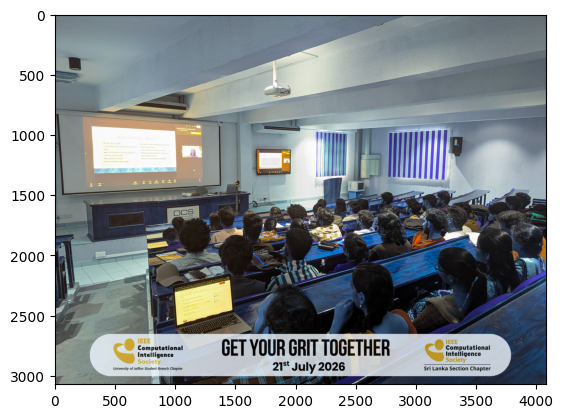

In [41]:
frame = cv2.imread("../resources/6.jpg")

#bgr to rgb conversion 
#cv2 -rgb, YOLO -rgb
frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
plt.imshow(frame)

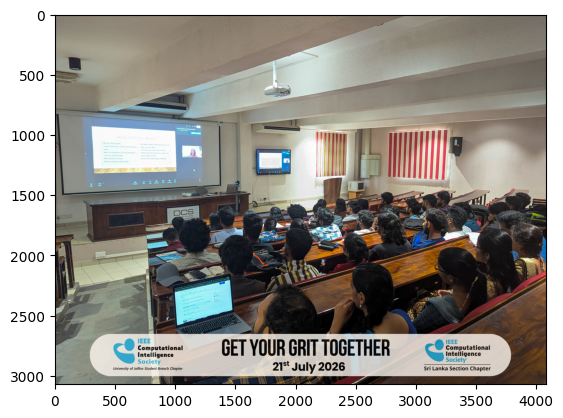

In [42]:
plt.imshow(frame_rgb)

2. **Brightness adjustment with CLAHE (Contrast Limited Adaptive Histogram Equalization)**

* why we use CLAHE for brightness adjustment? 

when we use CLAHE for brightness adjustment, it helps to enhance the contrast of the image while preventing over-amplification of noise in homogeneous areas. This is particularly useful in low-light conditions or when the image has varying lighting conditions, as it improves the visibility of features and details that may be important for object detection.

Brightness: 122.22058352800755


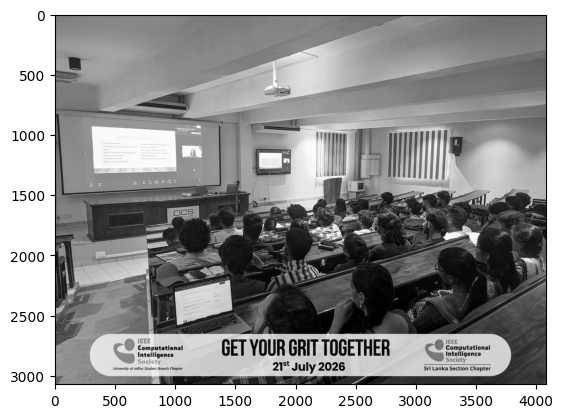

In [43]:
# convert to gray scale to get brightness level
frame_gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
brightness = np.mean(frame_gray)
plt.imshow(frame_gray, cmap="gray")
print(f"Brightness: {brightness}")

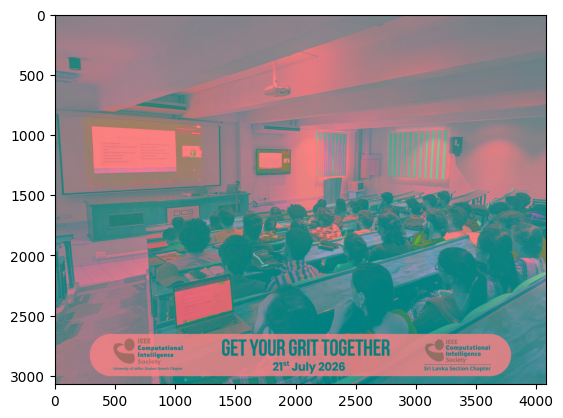

In [44]:
# CLAHE(for dark images, back row, shadow images students detection)
lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
plt.imshow(lab)

In [45]:
l, a, b = cv2.split(lab)
print(l, a, b)

[[128 129 134 ... 118 115 114]
 [122 131 136 ... 117 112 114]
 [125 133 134 ... 117 115 118]
 ...
 [112 112 113 ...  68  48  51]
 [115 114 113 ...  73  60  61]
 [115 113 112 ...  68  57  55]] [[130 130 130 ... 129 129 129]
 [130 130 130 ... 129 130 129]
 [130 130 130 ... 129 129 129]
 ...
 [124 124 123 ... 136 137 137]
 [124 123 123 ... 136 137 136]
 [124 123 124 ... 136 137 137]] [[134 134 134 ... 132 132 132]
 [134 134 134 ... 132 132 132]
 [134 134 134 ... 132 132 132]
 ...
 [130 130 130 ... 141 142 141]
 [130 130 130 ... 140 141 141]
 [130 130 130 ... 141 141 141]]


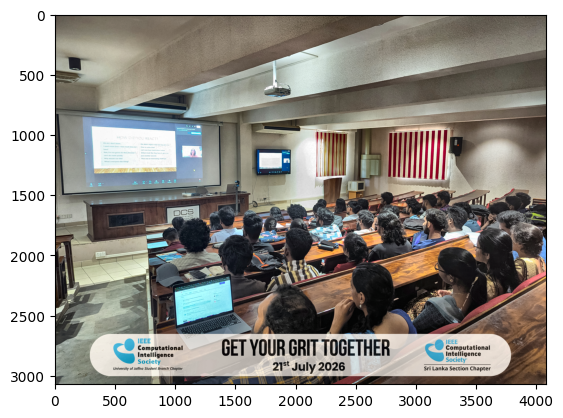

In [46]:
# initialize clahe params.
clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8,8)
)

l = clahe.apply(l)

lab = cv2.merge((l,a,b))

frame_rgb_after_clahe = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)
plt.imshow(frame_rgb_after_clahe)


In [47]:
# if images are darken apply CLAHE

if brightness < 80:
    lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)

    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8,8)
    )

    l = clahe.apply(l)

    lab = cv2.merge((l,a,b))

    frame_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    

3. **Resize and Padding**

* Why we use padding, when resizing the image to a fixed size?

When resizing an image to a fixed size, the aspect ratio of the original image may not match the target size. This can lead to distortion or stretching of the image, which can negatively impact the performance of object detection models. To address this issue, padding is used to maintain the aspect ratio of the original image while resizing it to the desired dimensions.

In [48]:
print(frame_rgb.shape)

# Get height and width from original frame shape
height, width = frame_rgb.shape[:2]
print(f"Original Height: {height}, Width: {width}")

# target size for YOLO model
new_shape=(640,640) 

# calculate aspect ratio scaling factor - (New image height or width / Old image height or width)
ratio = min(new_shape[0]/height, new_shape[1]/width) 

# compute new unpadded dimensions
new_unpad = int(round(width * ratio)), int(round(height * ratio))
dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]  # wh padding

# divide padding into 2 sides
dw /= 2  
dh /= 2

(3072, 4080, 3)
Original Height: 3072, Width: 4080


Resized image shape: (482, 640, 3)


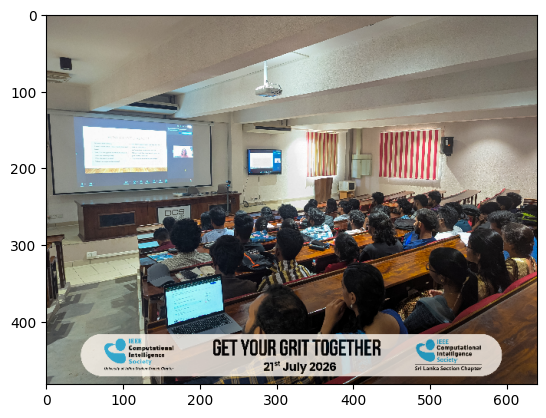

In [49]:
# resize image maintaining aspect ratio
if shape_hw := (width, height) != new_unpad:
    resized_frame = cv2.resize(frame_rgb, new_unpad, interpolation=cv2.INTER_LINEAR)
else:
    resized_frame = frame_rgb

print(f"Resized image shape: {resized_frame.shape}")       
plt.imshow(resized_frame)

In [50]:
# Calculate padding for both sides (letterboxing to 640x640)
top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
left, right = int(round(dw - 0.1)), int(round(dw + 0.1))

Padded Image Shape: (640, 640, 3)


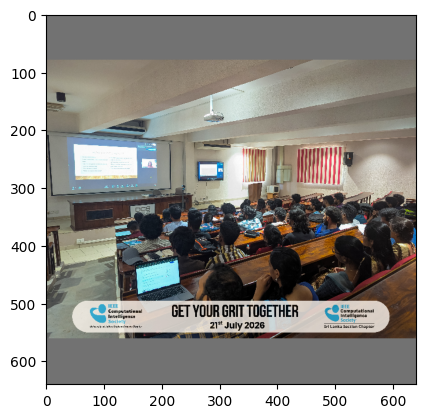

In [51]:

# Add constant gray border (value 114 standard for YOLO)
frame_padded = cv2.copyMakeBorder(resized_frame, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))

print(f"Padded Image Shape: {frame_padded.shape}")
plt.imshow(frame_padded)

### **Normalization and Tensor Formatting**

4. **Normalization**

for yolo11 model, the input image is normalized to a range of [0, 1] by dividing the pixel values by 255. This normalization step is important because it helps the model to converge faster during training and improves its performance during inference. Normalization also ensures that the input data is consistent with the data distribution that the model was trained on, which can lead to better generalization and accuracy.

In [52]:
# Normalize pixel values to range [0, 1]
frame_normalized = frame_padded.astype(np.float32) / 255.0

5. **Transpose (HWC to CHW)**

for yolo11 model, the input image is transposed from the shape (height, width, channels) to (channels, height, width). This is necessary because the model expects the input in a specific format, and transposing ensures that the data is correctly structured for processing by the neural network.

In [53]:
# Transpose dimensions from HWC (Height, Width, Channel) to CHW (Channel, Height, Width)
frame_transposed = np.transpose(frame_normalized, (2, 0, 1))

# Add batch dimension to match ONNX model input requirement: [1, 3, 640, 640]
input_tensor = np.expand_dims(frame_transposed, axis=0)

print(f"Final Input Tensor Shape: {input_tensor.shape}")
print(f"Data Type: {input_tensor.dtype}")

Final Input Tensor Shape: (1, 3, 640, 640)
Data Type: float32


## **Preprocessing Function**

Single preprocessing function is created to perform all the above preprocessing steps in a single function. This function takes an input image and returns the preprocessed image ready for inference.

In [54]:
def preprocess(frame, new_shape=(640, 640)):
    """
    Complete preprocessing pipeline for YOLO models running via ONNX Runtime:
    1. BGR to RGB color conversion
    2. Optional CLAHE brightness enhancement for dark/shadowed images
    3. Aspect-ratio-preserving resizing with letterbox padding
    4. Normalization [0, 1]
    5. Transpose (HWC to CHW) and Batch dimension expansion
    """
    
    # 1. BGR to RGB conversion
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    # 2. Brightness check and optional CLAHE enhancement
    frame_gray = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2GRAY)
    brightness = np.mean(frame_gray)

    if brightness < 80:
        lab = cv2.cvtColor(frame_rgb, cv2.COLOR_RGB2LAB)
        l, a, b = cv2.split(lab)

        clahe = cv2.createCLAHE(
            clipLimit=2.0,
            tileGridSize=(8, 8)
        )
        l = clahe.apply(l)

        lab = cv2.merge((l, a, b))
        frame_rgb = cv2.cvtColor(lab, cv2.COLOR_LAB2RGB)

    # 3. Resize and Letterbox Padding
    height, width = frame_rgb.shape[:2]

    # Calculate scale ratio (New / Old)
    ratio = min(new_shape[0] / height, new_shape[1] / width)

    # Compute unpadded dimensions
    new_unpad = (int(round(width * ratio)), int(round(height * ratio)))
    
    # Compute padding width/height differences
    dw, dh = new_shape[1] - new_unpad[0], new_shape[0] - new_unpad[1]  

    # Divide padding into two equal sides
    dw /= 2  
    dh /= 2

    # Resize image if dimensions don't match unpadded target size
    if (width, height) != new_unpad:
        im = cv2.resize(frame_rgb, new_unpad, interpolation=cv2.INTER_LINEAR)
    else:
        im = frame_rgb

    top, bottom = int(round(dh - 0.1)), int(round(dh + 0.1))
    left, right = int(round(dw - 0.1)), int(round(dw + 0.1))

    # Add constant gray border (value 114 is standard for YOLO models)
    im = cv2.copyMakeBorder(im, top, bottom, left, right, cv2.BORDER_CONSTANT, value=(114, 114, 114))  
    
    # 4. Normalization and Transpose (HWC to CHW) + Batch expansion
    img = im.astype(np.float32) / 255.0
    img = np.transpose(img, (2, 0, 1))
    img = np.expand_dims(img, axis=0)
    
    return img, ratio, (dw, dh)

# **Start ONNX runtime session**

In [55]:
#initialize onnx session
session = ort.InferenceSession(onnx_path, providers=['CPUExecutionProvider'])

## **Running ONNX Inference**

In this step, we pass the preprocessed input tensor (or preprocess function named img) into the ONNX Runtime inference session to get the model predictions.

In [56]:
# get input and output names from the onnx session
input_name = session.get_inputs()[0].name
output_name = session.get_outputs()[0].name

# run inference
outputs = session.run([output_name], {input_name: input_tensor})
predictions = outputs[0]

print(f"Inference Successful!")
print(f"Predictions Output Shape: {predictions.shape}")

Inference Successful!
Predictions Output Shape: (1, 84, 8400)


## **Inference and Visualization on Sample Image**

In this step, we load a sample image (`/resource`), run our preprocessing pipeline, perform ONNX inference, map the letterbox bounding box coordinates back to the original image dimensions, apply NMS, and visualize the final detections along with the classroom occupancy and smart AC/cooling system state.

Pinged your deployment. You successfully connected to MongoDB!

[STUDENT COUNT: 32] -> MEDIUM (Half filled)
 Target Temp : 22.0°C – 23.0°C
 AC Units    : AC 4 ON (Normal)
 Fan Speed   : MEDIUM
 Air Flow    : SWING
Captured frame saved locally: ../Frame_captures/classroom_2026-08-06_23-02-06_count_32.jpg
Structured HVAC telemetry successfully logged to MongoDB Atlas!



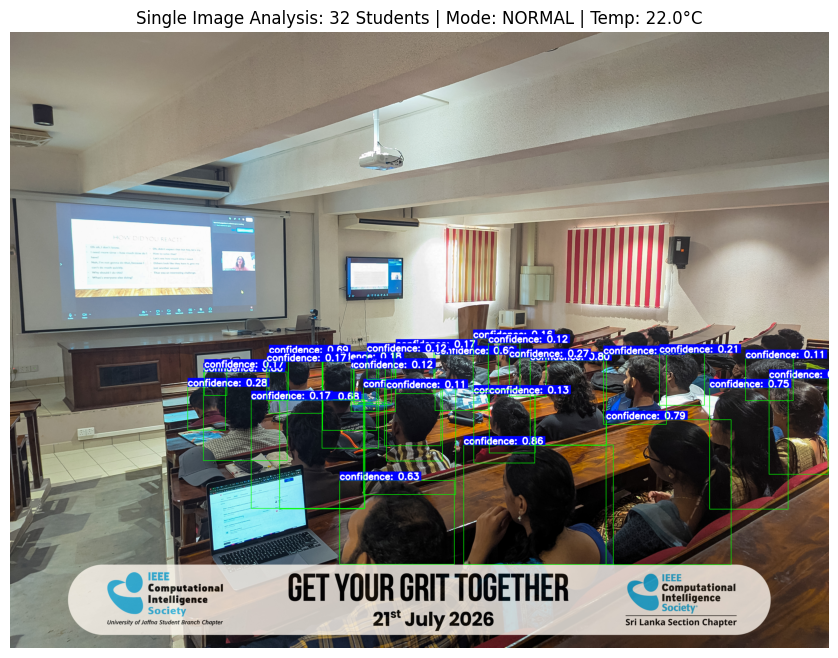

In [ ]:
import cv2
import numpy as np
import os
from datetime import datetime
from pymongo import MongoClient
import certifi # prevent db timeout
from dotenv import load_dotenv
import matplotlib.pyplot as plt

# ==========================================
# 1. MONGODB CONNECTION ESTABLISHMENT
# ==========================================
load_dotenv()

DB_NAME = os.getenv("DB_NAME")
COLLECTION_NAME = os.getenv("COLLECTION_NAME")
CONNECTION_URI = os.getenv("MONGODB_URI")

client = MongoClient(CONNECTION_URI, tlsCAFile=certifi.where())
 
try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(f"Connection warning: {e}")

# initilize database,collection and push data dicts. to mongodb atlas db
data_base = client[DB_NAME]
collection = data_base[COLLECTION_NAME]



# ==========================================
# 2. NMS PARAMETERS
# ==========================================
CONFIDENCE_THRESHOLD = 0.10
NMS_THRESHOLD = 0.75



# ============================================================================
# 3. INFERENCE & DETECTION FUNCTION WITH NON-MAXIMUM SUPPRESSION (NMS)
# ============================================================================
def run_detection(frame):
    h_orig, w_orig = frame.shape[:2]

    # preprocess input frame
    input_tensor, r, (dw, dh) = preprocess(frame)

    # run ONNX model inference
    outputs = session.run(None, {input_name: input_tensor})
    preds = np.squeeze(outputs[0]).T

    boxes = []
    confidences = []
    class_ids = []

    for row in preds: 
        classes_scores = row[4:]
        max_score = np.max(classes_scores)
        class_id = np.argmax(classes_scores)

        if class_id == 0 and max_score >= CONFIDENCE_THRESHOLD:
            cx, cy, bw, bh = row[0], row[1], row[2], row[3]

            # map letterbox coordinates back to original image dimensions
            x1 = int((cx - bw/2 - dw) / r)
            y1 = int((cy - bh/2 - dh) / r)
            x2 = int((cx + bw/2 - dw) / r)
            y2 = int((cy + bh/2 - dh) / r)

            w_box = x2 - x1
            h_box = y2 - y1

            boxes.append([x1, y1, w_box, h_box])
            confidences.append(float(max_score))
            class_ids.append(class_id)

    # Non-Maximum Suppression (NMS) to remove extra boxes
    indices = cv2.dnn.NMSBoxes(boxes, confidences, score_threshold=CONFIDENCE_THRESHOLD, nms_threshold=NMS_THRESHOLD)

    detected_boxes = []
    if len(indices) > 0:
        for i in indices.flatten():
            x, y, w_box, h_box = boxes[i]
            conf = confidences[i] # get respective confidence score
            x1 = max(0, x)
            y1 = max(0, y)
            x2 = min(w_orig, x + w_box)
            y2 = min(h_orig, y + h_box)
            detected_boxes.append((x1, y1, x2, y2, conf))

    detected_count = len(detected_boxes)

    return detected_boxes, detected_count




# ==========================================
# 4. COOLING CONTROL FUNCTION
# ==========================================
def regulate_cooling_system(detected_count):
    """
    Controls 4 AC units, temperatures, fan speeds, and louvers based on the Smart Classroom Operation Matrix.
    This returns structured data dictionaries
    """
    if 0 <= detected_count <= 20:
        hvac_data = {
            "occupancy_level": "low",
            "ac_status_text": "AC 2 ON (Alternate)",
            "ac_active_count": 2,
            "ac_mode": "alternate",
            "temp_min": 24.0,
            "temp_max": 25.0,
            "fan_speed": "low",
            "louver_position": "down",
            "description": "LOW (Pre-lecture / Small group)"
        }
        
    elif 21 <= detected_count <= 60:
        hvac_data = {
            "occupancy_level": "medium",
            "ac_status_text": "AC 4 ON (Normal)",
            "ac_active_count": 4,
            "ac_mode": "normal",
            "temp_min": 22.0,
            "temp_max": 23.0,
            "fan_speed": "medium",
            "louver_position": "swing",
            "description": "MEDIUM (Half filled)"
        }
        
    elif 61 <= detected_count <= 110:
        hvac_data = {
            "occupancy_level": "high",
            "ac_status_text": "AC 4 ON (Active)",
            "ac_active_count": 4,
            "ac_mode": "active",
            "temp_min": 20.0,
            "temp_max": 21.0,
            "fan_speed": "high",
            "louver_position": "horizontal",
            "description": "HIGH (Well filled)"
        }
        
    else: # 111 - 150+
        hvac_data = {
            "occupancy_level": "full",
            "ac_status_text": "AC 4 ON (Full Power / Turbo)",
            "ac_active_count": 4,
            "ac_mode": "turbo",
            "temp_min": 17.0,
            "temp_max": 19.0,
            "fan_speed": "max",
            "louver_position": "all_swing_fresh_air",
            "description": "FULL (Maximum capacity)"
        }

    # Print Detailed Status to Console
    print(f"\n[STUDENT COUNT: {detected_count}] -> {hvac_data['description']}")
    print(f" Target Temp : {hvac_data['temp_min']}°C – {hvac_data['temp_max']}°C")
    print(f" AC Units    : {hvac_data['ac_status_text']}")
    print(f" Fan Speed   : {hvac_data['fan_speed'].upper()}")
    print(f" Air Flow    : {hvac_data['louver_position'].upper()}")
    
    return hvac_data



# ==========================================
# 5. SAVE ANNOTATED FRAME FUNCTION
# ==========================================
def save_annotated_frame(frame, detected_boxes, person_count, hvac_data):

    # create dir for saving captured frame if not exist
    capture_dir = "../Frame_captures"
    os.makedirs(capture_dir, exist_ok=True)

    # create a copy to avoid drawing issues on the main display frame
    frame_copy = frame.copy()

    # draw bounding boxes with labels
    for (x1, y1, x2, y2, conf) in detected_boxes:
        cv2.rectangle(frame_copy, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # label formatting 
        label = f"confidence: {conf:.2f}"
        font_scale = 0.6
        font_thickness = 2
        
        (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, font_thickness)
        
        box_x1 = x1
        box_y1 = y1 - text_height - 10
        box_x2 = x1 + text_width + 5
        box_y2 = y1
        
        # background box for label
        cv2.rectangle(frame_copy, (box_x1, box_y1), (box_x2, box_y2), (0, 0, 255), -1)
        
        # label text
        cv2.putText(
            frame_copy, 
            label, 
            (x1, y1 - 5), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            font_scale, 
            (255, 255, 255), 
            font_thickness, 
            cv2.LINE_AA
        )

    # get current timestamps
    timestamp_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    file_timestamp_str = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

    # overlay summary info on the frame
    info_text = f"Time: {timestamp_str} | Count: {person_count} | Temp: {hvac_data['temp_min']}C"
    cv2.putText(frame_copy, info_text, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 255, 255), 2, cv2.LINE_AA)

    # save the processed frame in local dir
    filename = f"{capture_dir}/classroom_{file_timestamp_str}_count_{person_count}.jpg"
    cv2.imwrite(filename, frame_copy)
    print(f"Captured frame saved locally: {filename}")
    
    return filename, timestamp_str




# ===============================================================
# 6. CLOUD DATABASE LOGGING FUNCTION (MONGODB ATLAS)
# ===============================================================
def db_system_logging(person_count, hvac_data, image_path, timestamp_str):
    log_document = {
        "timestamp": timestamp_str,
        "student_count": person_count,
        "occupancy_level": hvac_data["occupancy_level"],
        "hvac_control": {
            "ac_active_count": hvac_data["ac_active_count"],
            "ac_mode": hvac_data["ac_mode"],
            "target_temp_min": hvac_data["temp_min"],
            "target_temp_max": hvac_data["temp_max"],
            "fan_speed": hvac_data["fan_speed"],
            "louver_position": hvac_data["louver_position"]
        },
        "image_path": image_path
    }
    
    try:
        collection.insert_one(log_document)
        print(f"Structured HVAC telemetry successfully logged to MongoDB Atlas!\n")
    except Exception as e:
        print(f"Failed to insert data into MongoDB: {e}\n")




# ==========================================
# 7. EXECUTION ON SINGLE IMAGE
# ==========================================
image_path = "../resources/6.jpg"  # Target image path
frame = cv2.imread(image_path)     # Load image

if frame is not None:
    # 1. run AI Detection
    detected_boxes, person_count = run_detection(frame)
    
    # 2. regulate cooling system based on matrix (returns structured dict)
    hvac_data = regulate_cooling_system(person_count)
    
    # 3. save annotated frame locally
    saved_image_path, timestamp_str = save_annotated_frame(frame, detected_boxes, person_count, hvac_data)
    
    # 4. log structured data to MongoDB Atlas
    db_system_logging(person_count, hvac_data, saved_image_path, timestamp_str)
    
    # 5. Display output using Matplotlib
    frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # draw bounding boxes and confidence on RGB copy for visualization
    for (x1, y1, x2, y2, conf) in detected_boxes:
        cv2.rectangle(frame_rgb, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # label formatting 
        label = f"confidence: {conf:.2f}"
        font_scale = 1.5
        font_thickness = 5
                
        (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, font_thickness)
                
        box_x1 = x1
        box_y1 = y1 - text_height - 10
        box_x2 = x1 + text_width + 5
        box_y2 = y1
                
        # background box for label
        cv2.rectangle(frame_rgb, (box_x1, box_y1), (box_x2, box_y2), (0, 0, 255), -1)
                
        # label text
        cv2.putText(
            frame_rgb, 
            label, 
            (x1, y1 - 5), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            font_scale, 
            (255, 255, 255), 
            font_thickness, 
            cv2.LINE_AA
        )
        
    plt.figure(figsize=(12, 8))
    plt.imshow(frame_rgb)
    plt.axis('off')
    plt.title(f"Single Image Analysis: {person_count} Students | Mode: {hvac_data['ac_mode'].upper()} | Temp: {hvac_data['temp_min']}°C")
    plt.show()

else:
    print(f"Error: Could not load image from {image_path}")

# **From Image to Video Analysis**
After successfully testing and implementing our YOLO object detection and smart cooling logic on a single classroom image, we are now scaling it up to **real-time video processing**. 

To optimize performance, instead of running the AI model on every single frame, we implement an **interval-based detection approach** (e.g., every 5 minutes / 300 seconds). Captured frames are automatically annotated with student counts, timestamps, saved locally, and logged to MongoDB Atlas.

### 1. Setup Local Storage, and Database Connection
Before video-processing we shold create a local directory for saving frames, and connect to MongoDB Atlas to store tracking logs if future analysis is needed.

In [ ]:
import cv2
import numpy as np
import os
from pymongo import MongoClient
import certifi # prevent db timeout
from dotenv import load_dotenv



In [34]:
# mongodb connection establishment
load_dotenv()

DB_NAME= os.getenv("DB_NAME")
COLLECTION_NAME= os.getenv("COLLECTION_NAME")
CONNECTION_URI= os.getenv("MONGODB_URI")

client= MongoClient(CONNECTION_URI, tlsCAFile=certifi.where())
 
try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(e)

# initilize database,collection and push data dicts. to mongodb atlas db
data_base = client[DB_NAME]
collection = data_base[COLLECTION_NAME]


Pinged your deployment. You successfully connected to MongoDB!


### 2. Initialize Video Capture Source
Load your pre-recorded video file or use `0` to switch to a live webcam stream.

In [35]:
video_path = "#"
cap = cv2.VideoCapture(video_path)

if not cap.isOpened():
    print("Error: Could not open video source.")
else:
    print("Video stream initialized successfully.")

Error: Could not open video source.


### 3. Inference & Detection Function with Non-Maximum Suppression (NMS) 
Defines the function to run model inference, map letterbox coordinates back to the original size, and apply NMS.

In [ ]:
# NMS params
CONFIDENCE_THRESHOLD = 0.10
NMS_THRESHOLD = 0.75

def run_detection(frame):
    h_orig, w_orig = frame.shape[:2]

    # preprocess input frame
    input_tensor, r, (dw, dh) = preprocess(frame)

    # run ONNX model inference
    outputs = session.run(None, {input_name: input_tensor})
    preds = np.squeeze(outputs[0]).T

    boxes = []
    confidences = []
    class_ids = []

    for row in preds:
        classes_scores = row[4:]
        max_score = np.max(classes_scores)
        class_id = np.argmax(classes_scores)

        if class_id == 0 and max_score >= CONFIDENCE_THRESHOLD:
            cx, cy, bw, bh = row[0], row[1], row[2], row[3]

            # map letterbox coordinates back to original image dimensions
            x1 = int((cx - bw/2 - dw) / r)
            y1 = int((cy - bh/2 - dh) / r)
            x2 = int((cx + bw/2 - dw) / r)
            y2 = int((cy + bh/2 - dh) / r)

            w_box = x2 - x1
            h_box = y2 - y1

            boxes.append([x1, y1, w_box, h_box])
            confidences.append(float(max_score))
            class_ids.append(class_id)


    # Non-Maximum Suppression (NMS) for remove extra boxes
    indices = cv2.dnn.NMSBoxes(boxes, confidences, score_threshold=CONFIDENCE_THRESHOLD, nms_threshold=NMS_THRESHOLD)

    detected_boxes = []
    if len(indices) > 0:
        for i in indices.flatten():
            x, y, w_box, h_box = boxes[i]
            conf = confidences[i] # get respective confidence score
            x1 = max(0, x)
            y1 = max(0, y)
            x2 = min(w_orig, x + w_box)
            y2 = min(h_orig, y + h_box)
            detected_boxes.append((x1, y1, x2, y2, conf))

    detected_count = len(detected_boxes)


    return detected_boxes, detected_count


In [ ]:
# pass count

### 4. Cooling Control Function 
Manages the AC state and classroom occupancy level based on student count.

- class room maximum capacity = 150 students

- each classroom has 4 AC units, and each AC unit can cool up to 50 students. The cooling control function determines the number of AC units to turn on based on the current student count, ensuring optimal cooling while minimizing energy consumption.



**Advanced 4-AC Matrix Cooling Control**

HVAC Operation Matrix  controls 4 AC units, temperatures, fan speeds, louvers, and swing modes based on precise student density brackets, alongside database logging.

In [ ]:
def regulate_cooling_system(detected_count):
    """
    Controls 4 AC units, temperatures, fan speeds, and louvers based on the Smart Classroom Operation Matrix.
    This returns structured data dictionaries
    """

    if 0 <= detected_count <= 20:
        hvac_data = {
            "occupancy_level": "low",
            "ac_status_text": "AC 2 ON (Alternate)",
            "ac_active_count": 2,
            "ac_mode": "alternate",
            "temp_min": 24.0,
            "temp_max": 25.0,
            "fan_speed": "low",
            "louver_position": "down",
            "description": "LOW (Pre-lecture / Small group)"
        }

    elif 21 <= detected_count <= 60:
        hvac_data = {
            "occupancy_level": "medium",
            "ac_status_text": "AC 4 ON (Normal)",
            "ac_active_count": 4,
            "ac_mode": "normal",
            "temp_min": 22.0,
            "temp_max": 23.0,
            "fan_speed": "medium",
            "louver_position": "swing",
            "description": "MEDIUM (Half filled)"
        }

    elif 61 <= detected_count <= 110:
        hvac_data = {
            "occupancy_level": "high",
            "ac_status_text": "AC 4 ON (Active)",
            "ac_active_count": 4,
            "ac_mode": "active",
            "temp_min": 20.0,
            "temp_max": 21.0,
            "fan_speed": "high",
            "louver_position": "horizontal",
            "description": "HIGH (Well filled)"
        }

    else: # 111 - 150+
        hvac_data = {
            "occupancy_level": "full",
            "ac_status_text": "AC 4 ON (Full Power / Turbo)",
            "ac_active_count": 4,
            "ac_mode": "turbo",
            "temp_min": 17.0,
            "temp_max": 19.0,
            "fan_speed": "max",
            "louver_position": "all_swing_fresh_air",
            "description": "FULL (Maximum capacity)"
        }

    # print status
    print(f"\n[STUDENT COUNT: {detected_count}] -> {hvac_data['description']}")
    print(f" Target Temp : {hvac_data['temp_min']}°C – {hvac_data['temp_max']}°C")
    print(f" AC Units    : {hvac_data['ac_status_text']}")
    print(f" Fan Speed   : {hvac_data['fan_speed'].upper()}")
    print(f" Air Flow    : {hvac_data['louver_position'].upper()}")
    
    return hvac_data

In [ ]:
# pass run_detection() params, requlate_cooling_system() params

### 5. Save Annotated frames Function 

for future analysis, we save the annotated frames with bounding boxes, student counts, and timestamps to a local directory. This allows for easy retrieval and review of past classroom occupancy data.

In [ ]:
from datetime import datetime

# draws bounding boxes, overlays summary info, and saves the frame locally
def save_annotated_frame(frame, detected_boxes, person_count, hvac_data):

    # create dir for save captured frame if not exist
    capture_dir = "../Frame_captures"
    os.makedirs(capture_dir, exist_ok=True)

    # create a copy to avoid drawing issues on the main display frame if needed
    frame_copy = frame.copy()

    # draw bounding boxes with labels
    for (x1, y1, x2, y2) in detected_boxes:
        cv2.rectangle(frame_copy, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # label formatting 
        label = f"confidence: {conf:.2f}"
        font_scale = 0.6
        font_thickness = 2
        
        (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, font_thickness)
        
        box_x1 = x1
        box_y1 = y1 - text_height - 10
        box_x2 = x1 + text_width + 5
        box_y2 = y1
        
        # background box for label
        cv2.rectangle(frame_copy, (box_x1, box_y1), (box_x2, box_y2), (0, 0, 255), -1)
        
        # label text
        cv2.putText(
            frame_copy, 
            label, 
            (x1, y1 - 5), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            font_scale, 
            (255, 255, 255), 
            font_thickness, 
            cv2.LINE_AA
        )

    # get current timestamps
    timestamp_str = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    file_timestamp_str = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

    # overlay summary info on the frame
    info_text = f"Time: {timestamp_str} | Count: {person_count} | Temp: {hvac_data['temp_min']}C"
    cv2.putText(frame_copy, info_text, (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 255), 2, cv2.LINE_AA)

    # save the processed frame locally
    filename = f"{capture_dir}/classroom_{file_timestamp_str}_count_{person_count}.jpg"
    cv2.imwrite(filename, frame_copy)
    print(f"captured frame saved locally: {filename}")
    
    return filename, timestamp_str


### 5. Cloud Database Logging Function

for future analysis, we log the annotated frames with bounding boxes, student counts, and timestamps to a cloud database (MongoDB Atlas). This allows for easy retrieval and review of past classroom occupancy data, as well as enabling further analysis and insights into classroom usage patterns over time.

In [ ]:
# pushes clean structured HVAC metadata to MongoDB Atlas for analytics.
def db_system_logging(person_count, hvac_data, image_path, timestamp_str):
    log_document = {
        "timestamp": timestamp_str,
        "student_count": person_count,
        "occupancy_level": hvac_data["occupancy_level"],
        "hvac_control": {
            "ac_active_count": hvac_data["ac_active_count"],
            "ac_mode": hvac_data["ac_mode"],
            "target_temp_min": hvac_data["temp_min"],
            "target_temp_max": hvac_data["temp_max"],
            "fan_speed": hvac_data["fan_speed"],
            "louver_position": hvac_data["louver_position"]
        },
        "image_path": image_path
    }
    
    try:
        collection.insert_one(log_document)
        print(f"Structured HVAC telemetry successfully logged to MongoDB Atlas!\n")
    except Exception as e:
        print(f"Failed to insert data into MongoDB: {e}\n")

### 6: Run Real-Time Video Loop with All detection and control functions
The main execution loop that sequentially coordinates AI inference, 4-AC matrix control, local frame saving, and cloud db logging.

implement an **interval-based detection approach**. so, we can set the detection interval to every 5 minutes (300 seconds) or any other suitable duration based on the specific requirements of the classroom environment.

In [ ]:
import time

# set interval for 5 minutes
INTERVAL_SECONDS = 300 
last_checked_time = 0

print("\nStarting smart classroom HVAC system. Press 'q' in the video window to exit.")

while cap.isOpened():
    ret, frame = cap.read()
    if not ret:
        print("Video ended or failed to grab frame.")
        break
        
    current_time = time.time()
    
    # check if the interval has passed - every 5 minutes
    if current_time - last_checked_time >= INTERVAL_SECONDS or last_checked_time == 0:
        print(f"\nInterval reached. Running AI detection & HVAC adjustment...")
        
        # 1. run AI detection
        boxes = run_detection(frame)
        person_count = len(boxes)
        
        # regulate cooling system based on matrix (Returns Structured Dict)
        hvac_data = regulate_cooling_system(person_count)
        
        # 2. save frame locally
        image_path, timestamp_str = save_annotated_frame(frame, boxes, person_count, hvac_data)
        
        # 3. log structured data to MongoDB Atlas
        db_system_logging(person_count, hvac_data, image_path, timestamp_str)
        
        # update last checked time
        last_checked_time = current_time

    # display the live video feed
    cv2.imshow("Smart Classroom Video Analysis", frame)

    # draw bounding boxes and confidence on RGB copy for visualization
    for (x1, y1, x2, y2, conf) in detected_boxes:
        cv2.rectangle(frame, (x1, y1), (x2, y2), (0, 255, 0), 2)

        # label formatting 
        label = f"confidence: {conf:.2f}"
        font_scale = 1.5
        font_thickness = 5
                
        (text_width, text_height), baseline = cv2.getTextSize(label, cv2.FONT_HERSHEY_SIMPLEX, font_scale, font_thickness)
                
        box_x1 = x1
        box_y1 = y1 - text_height - 10
        box_x2 = x1 + text_width + 5
        box_y2 = y1
                
        # background box for label
        cv2.rectangle(frame, (box_x1, box_y1), (box_x2, box_y2), (0, 0, 255), -1)
                
        # label text
        cv2.putText(
            frame, 
            label, 
            (x1, y1 - 5), 
            cv2.FONT_HERSHEY_SIMPLEX, 
            font_scale, 
            (255, 255, 255), 
            font_thickness, 
            cv2.LINE_AA
        )
    
    # exit loop if 'q' key is pressed
    if cv2.waitKey(1) & 0xFF == ord('q'):
        break

cap.release()
cv2.destroyAllWindows()
print("Video stream closed and system shut down safely.")